In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image

THRESHOLDS = [0.3, 0.5, 0.7]
PROB_DIR = Path("../results/comparison_probabilities")
PROJECT_ROOT = Path("..")

In [9]:
def calculate_metrics(prediction, ground_truth):
    prediction = prediction.astype(bool)
    ground_truth = ground_truth.astype(bool)

    intersection = np.logical_and(prediction, ground_truth).sum()
    union = np.logical_or(prediction, ground_truth).sum()

    iou = (intersection + 1e-7) / (union + 1e-7)

    dice = (2 * intersection + 1e-7) / (
        prediction.sum() + ground_truth.sum() + 1e-7
    )

    return iou, dice

In [10]:
def evaluate_thresholds(split):
    path = PROB_DIR / f"{split}.npz"

    with np.load(path, allow_pickle=False) as data:
        probabilities = data["probabilities"]
        mask_paths = data["mask_paths"]

    results = []

    for threshold in THRESHOLDS:
        total_intersection = 0
        total_union = 0
        total_prediction_sum = 0
        total_target_sum = 0

        for prob, mask_path in zip(probabilities, mask_paths):
            mask = np.array(
                Image.open(PROJECT_ROOT / str(mask_path)).convert("L")
            ) > 0

            prediction = prob[0] >= threshold

            total_intersection += np.logical_and(prediction, mask).sum()
            total_union += np.logical_or(prediction, mask).sum()
            total_prediction_sum += prediction.sum()
            total_target_sum += mask.sum()

        iou = total_intersection / (total_union + 1e-7)
        dice = 2 * total_intersection / (
            total_prediction_sum + total_target_sum + 1e-7
        )

        results.append({
            "model": "BCE + Dice",
            "split": split,
            "threshold": threshold,
            "global_iou": iou,
            "global_dice": dice
        })

    return pd.DataFrame(results)

In [11]:
val_results = evaluate_thresholds("val")
test_results = evaluate_thresholds("test")

threshold_results = pd.concat(
    [val_results, test_results],
    ignore_index=True
)

display(threshold_results.round(4))

,model,split,threshold,global_iou,global_dice
0,BCE + Dice,val,0.3,0.6199,0.7654
1,BCE + Dice,val,0.5,0.6160,0.7624
2,BCE + Dice,val,0.7,0.5988,0.7491
3,BCE + Dice,test,0.3,0.6718,0.8037
4,BCE + Dice,test,0.5,0.6681,0.8010
5,BCE + Dice,test,0.7,0.6473,0.7859


In [12]:
import pandas as pd
metrics_path = "../results/metrics/comparison_metrics.csv"
comparison_metrics = pd.read_csv(metrics_path)
display(comparison_metrics)

,model,encoder_weights,loss,dice_smooth,seed,batch_size,epochs,training_seconds,test_evaluation_seconds,optimizer,learning_rate,threshold,best_epoch,best_val_loss,best_val_iou,best_val_dice,test_loss,test_iou,test_dice
0,U-Net + ResNet18,ImageNet,BCEWithLogitsLoss + soft Dice,1.0,42,8,10,312.193538,1.487356,Adam,0.001,0.5,10,0.453489,0.616017,0.762389,0.444587,0.668093,0.801026


In [13]:
# Save threshold sensitivity results
output_dir = PROJECT_ROOT / "results" / "metrics"
output_dir.mkdir(parents=True, exist_ok=True)

threshold_results.to_csv(
    output_dir / "comparison_threshold_sensitivity.csv",
    index=False
)

print("Threshold sensitivity results saved.")

Threshold sensitivity results saved.


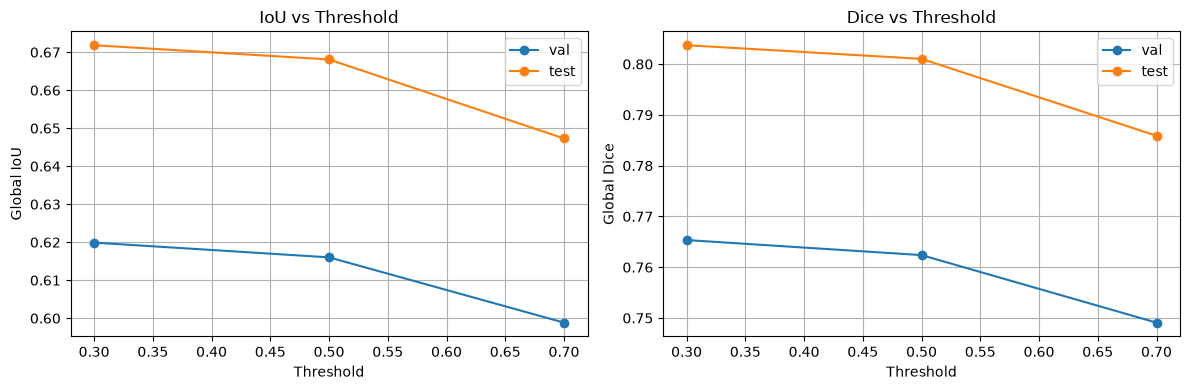

In [14]:
# Plot threshold sensitivity
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for split in ["val", "test"]:
    subset = threshold_results[
        threshold_results["split"] == split
    ]

    axes[0].plot(
        subset["threshold"],
        subset["global_iou"],
        marker="o",
        label=split
    )

    axes[1].plot(
        subset["threshold"],
        subset["global_dice"],
        marker="o",
        label=split
    )

axes[0].set_title("IoU vs Threshold")
axes[0].set_xlabel("Threshold")
axes[0].set_ylabel("Global IoU")
axes[0].legend()
axes[0].grid(True)

axes[1].set_title("Dice vs Threshold")
axes[1].set_xlabel("Threshold")
axes[1].set_ylabel("Global Dice")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()

figure_dir = PROJECT_ROOT / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    figure_dir / "comparison_threshold_sensitivity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

We evaluated the BCE + Dice model using three thresholds: 0.3, 0.5, and 0.7. The threshold of 0.3 achieved the highest IoU and Dice on the validation set. However, the improvement over the default threshold of 0.5 was small, suggesting that the model is relatively stable within this range.

In [15]:
# Find the worst predictions on the test set

with np.load(PROB_DIR / "test.npz", allow_pickle=False) as data:
    probabilities = data["probabilities"]
    image_paths = data["image_paths"]
    mask_paths = data["mask_paths"]

failure_results = []

for i, (prob, mask_path) in enumerate(zip(probabilities, mask_paths)):
    ground_truth = np.array(
        Image.open(PROJECT_ROOT / str(mask_path)).convert("L")
    ) > 0

    prediction = prob[0] >= 0.5

    iou, dice = calculate_metrics(prediction, ground_truth)

    failure_results.append({
        "index": i,
        "image_path": str(image_paths[i]),
        "mask_path": str(mask_path),
        "iou": iou,
        "dice": dice,
        "false_positive_pixels": int(
            np.logical_and(prediction, ~ground_truth).sum()
        ),
        "false_negative_pixels": int(
            np.logical_and(~prediction, ground_truth).sum()
        )
    })

failure_df = pd.DataFrame(failure_results)

display(
    failure_df.sort_values("iou").head(10)
)

,index,image_path,mask_path,iou,dice,false_positive_pixels,false_negative_pixels
267,267,data/processed/test/images/23729035_15_patch_1...,data/processed/test/masks/23729035_15_patch_15...,1.140251e-10,1.140251e-10,859,18
258,258,data/processed/test/images/23729035_15_patch_0...,data/processed/test/masks/23729035_15_patch_06...,2.557545e-10,2.557545e-10,391,0
67,67,data/processed/test/images/22828990_15_patch_3...,data/processed/test/masks/22828990_15_patch_31...,5.988024e-10,5.988024e-10,167,0
307,307,data/processed/test/images/23879080_15_patch_1...,data/processed/test/masks/23879080_15_patch_19...,1.754386e-09,1.754386e-09,0,57
286,286,data/processed/test/images/23729035_15_patch_3...,data/processed/test/masks/23729035_15_patch_34...,2.083333e-09,2.083333e-09,48,0
296,296,data/processed/test/images/23879080_15_patch_0...,data/processed/test/masks/23879080_15_patch_08...,2.083333e-09,2.083333e-09,0,48
306,306,data/processed/test/images/23879080_15_patch_1...,data/processed/test/masks/23879080_15_patch_18...,3.225806e-09,3.225806e-09,0,31
62,62,data/processed/test/images/22828990_15_patch_2...,data/processed/test/masks/22828990_15_patch_26...,3.571429e-09,3.571429e-09,0,28
113,113,data/processed/test/images/23429020_15_patch_0...,data/processed/test/masks/23429020_15_patch_05...,8.477152e-02,1.562938e-01,105,8327
216,216,data/processed/test/images/23579005_15_patch_0...,data/processed/test/masks/23579005_15_patch_00...,1.720280e-01,2.935561e-01,162,430


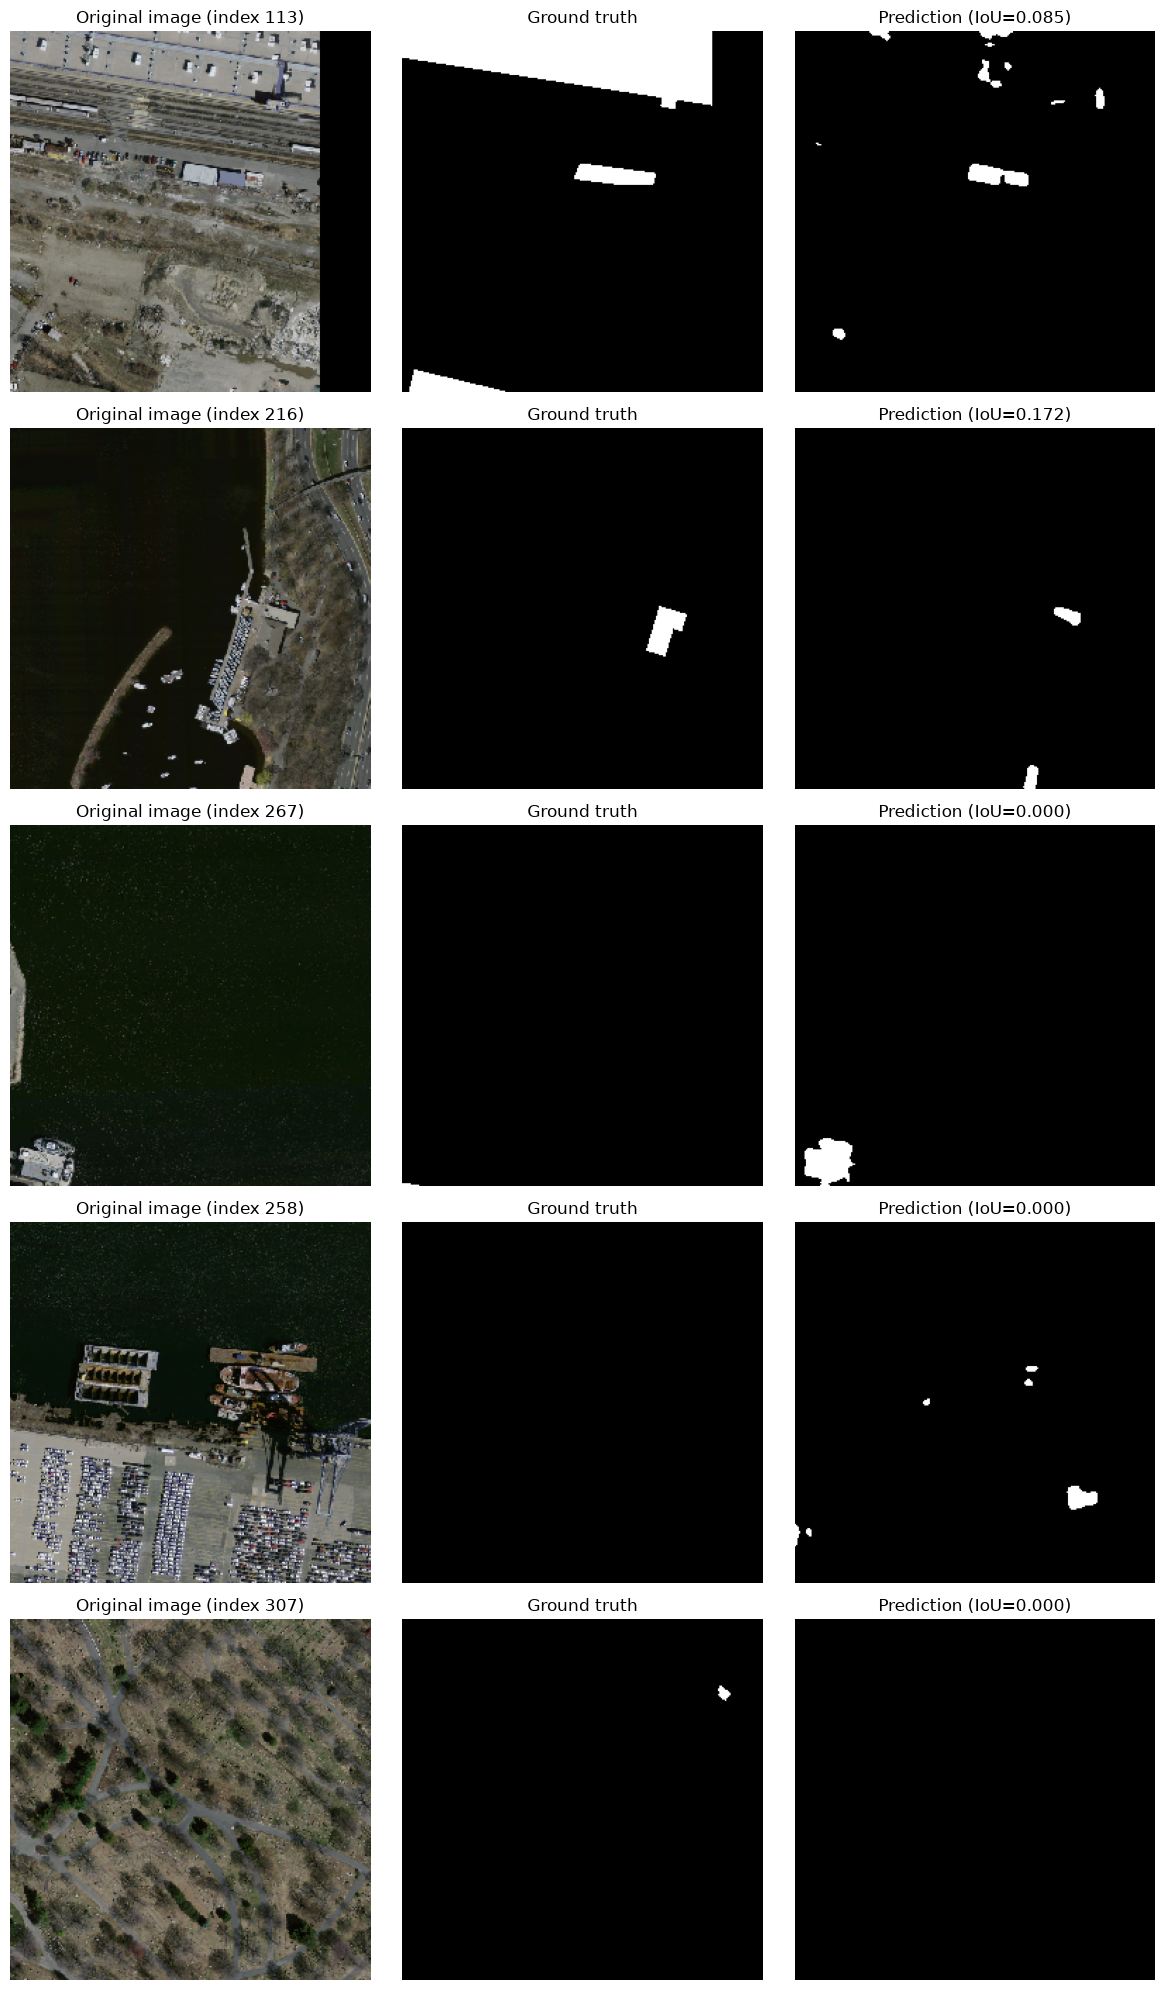

In [16]:
# Visualize candidate failure cases

candidate_indices = [113, 216, 267, 258, 307]

fig, axes = plt.subplots(
    len(candidate_indices), 3,
    figsize=(12, 4 * len(candidate_indices))
)

for row, idx in enumerate(candidate_indices):
    image = np.array(
        Image.open(PROJECT_ROOT / str(image_paths[idx])).convert("RGB")
    )

    ground_truth = np.array(
        Image.open(PROJECT_ROOT / str(mask_paths[idx])).convert("L")
    ) > 0

    prediction = probabilities[idx, 0] >= 0.5

    iou, dice = calculate_metrics(prediction, ground_truth)

    axes[row, 0].imshow(image)
    axes[row, 0].set_title(f"Original image (index {idx})")

    axes[row, 1].imshow(ground_truth, cmap="gray", vmin=0, vmax=1)
    axes[row, 1].set_title("Ground truth")

    axes[row, 2].imshow(prediction, cmap="gray", vmin=0, vmax=1)
    axes[row, 2].set_title(f"Prediction (IoU={iou:.3f})")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()

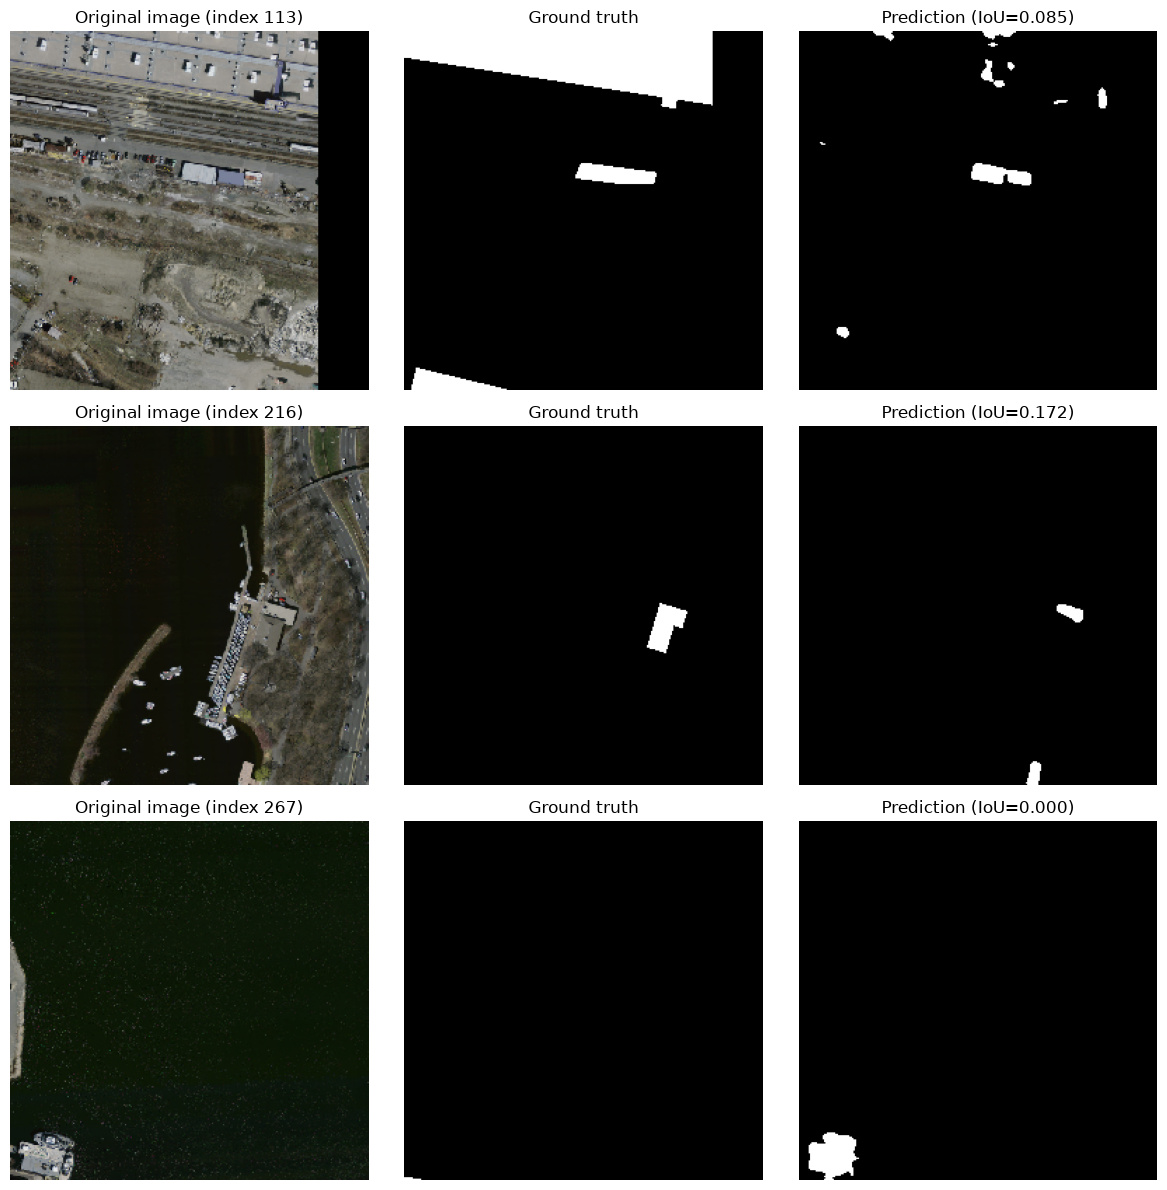

In [17]:
# Final failure analysis examples

selected_indices = [113, 216, 267]

fig, axes = plt.subplots(
    len(selected_indices), 3,
    figsize=(12, 12)
)

for row, idx in enumerate(selected_indices):
    image = np.array(
        Image.open(PROJECT_ROOT / str(image_paths[idx])).convert("RGB")
    )

    ground_truth = np.array(
        Image.open(PROJECT_ROOT / str(mask_paths[idx])).convert("L")
    ) > 0

    prediction = probabilities[idx, 0] >= 0.5

    iou, dice = calculate_metrics(prediction, ground_truth)

    axes[row, 0].imshow(image)
    axes[row, 0].set_title(f"Original image (index {idx})")

    axes[row, 1].imshow(ground_truth, cmap="gray", vmin=0, vmax=1)
    axes[row, 1].set_title("Ground truth")

    axes[row, 2].imshow(prediction, cmap="gray", vmin=0, vmax=1)
    axes[row, 2].set_title(f"Prediction (IoU={iou:.3f})")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()

figure_dir = PROJECT_ROOT / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    figure_dir / "comparison_failure_examples.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [18]:
def evaluate_model_thresholds(model_name, folder, split):
    data = np.load(
        PROJECT_ROOT / "results" / folder / f"{split}.npz"
    )

    probabilities = data["probabilities"]
    mask_paths = data["mask_paths"]

    results = []

    for threshold in THRESHOLDS:
        intersection = 0
        prediction_sum = 0
        target_sum = 0

        for probability, mask_path in zip(probabilities, mask_paths):
            prediction = probability[0] >= threshold

            ground_truth = np.asarray(
                Image.open(PROJECT_ROOT / str(mask_path)).convert("L")
            ) > 0

            intersection += np.logical_and(
                prediction, ground_truth
            ).sum()

            prediction_sum += prediction.sum()
            target_sum += ground_truth.sum()

        union = prediction_sum + target_sum - intersection

        iou = intersection / (union + 1e-7)
        dice = 2 * intersection / (
            prediction_sum + target_sum + 1e-7
        )

        results.append({
            "model": model_name,
            "split": split,
            "threshold": threshold,
            "global_iou": iou,
            "global_dice": dice,
        })

    return pd.DataFrame(results)


all_results = pd.concat([
    evaluate_model_thresholds(
        model_name,
        folder,
        split
    )
    for model_name, folder in [
        ("Baseline (BCE)", "baseline_probabilities"),
        ("BCE + Dice", "comparison_probabilities"),
    ]
    for split in ["val", "test"]
], ignore_index=True)

display(all_results.round(4))

,model,split,threshold,global_iou,global_dice
0,Baseline (BCE),val,0.3,0.6239,0.7684
1,Baseline (BCE),val,0.5,0.6338,0.7759
2,Baseline (BCE),val,0.7,0.5847,0.7380
3,Baseline (BCE),test,0.3,0.6783,0.8084
4,Baseline (BCE),test,0.5,0.6898,0.8164
5,Baseline (BCE),test,0.7,0.6440,0.7835
6,BCE + Dice,val,0.3,0.6199,0.7654
7,BCE + Dice,val,0.5,0.6160,0.7624
8,BCE + Dice,val,0.7,0.5988,0.7491
9,BCE + Dice,test,0.3,0.6718,0.8037


In [19]:
OUTPUT_DIR = PROJECT_ROOT / "results" / "metrics"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

all_results.to_csv(
    OUTPUT_DIR / "threshold_sensitivity_all_models.csv",
    index=False
)

print("Threshold sensitivity results saved.")

Threshold sensitivity results saved.


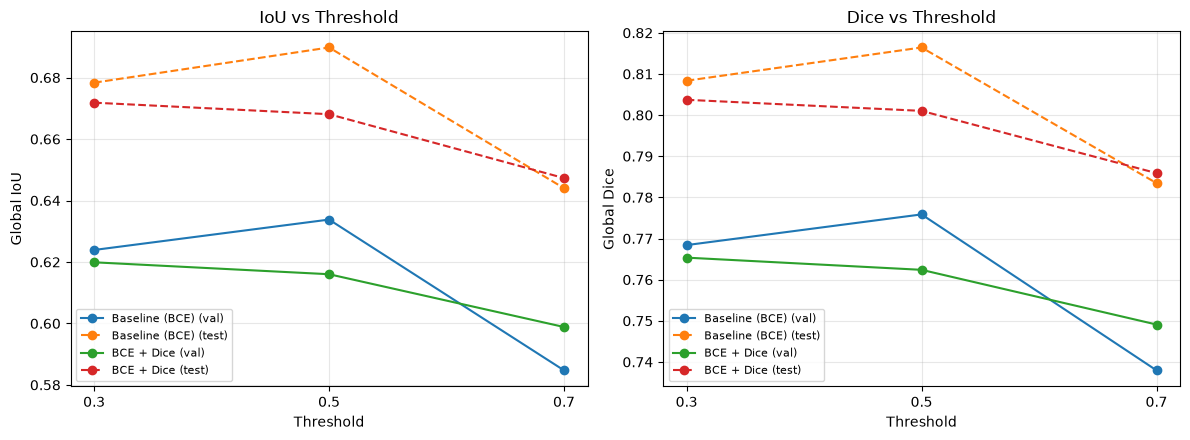

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for model_name in all_results["model"].unique():
    for split, linestyle in [("val", "-"), ("test", "--")]:
        subset = all_results[
            (all_results["model"] == model_name)
            & (all_results["split"] == split)
        ]

        label = f"{model_name} ({split})"

        axes[0].plot(
            subset["threshold"],
            subset["global_iou"],
            marker="o",
            linestyle=linestyle,
            label=label
        )

        axes[1].plot(
            subset["threshold"],
            subset["global_dice"],
            marker="o",
            linestyle=linestyle,
            label=label
        )

axes[0].set_title("IoU vs Threshold")
axes[0].set_xlabel("Threshold")
axes[0].set_ylabel("Global IoU")

axes[1].set_title("Dice vs Threshold")
axes[1].set_xlabel("Threshold")
axes[1].set_ylabel("Global Dice")

for ax in axes:
    ax.set_xticks(THRESHOLDS)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

plt.tight_layout()

FIGURES_DIR = PROJECT_ROOT / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

plt.savefig(
    FIGURES_DIR / "threshold_sensitivity_all_models.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

We evaluated both models using thresholds of 0.3, 0.5, and 0.7. The best threshold was selected based on validation IoU. For the baseline model, 0.5 achieved the highest validation IoU of 0.6338. For the BCE + Dice model, 0.3 performed best, with a validation IoU of 0.6199. On the test set, the baseline achieved an IoU of 0.6898 and Dice of 0.8164, outperforming BCE + Dice (IoU 0.6718, Dice 0.8037). These results show that adding Dice Loss did not improve segmentation performance in our experiments.

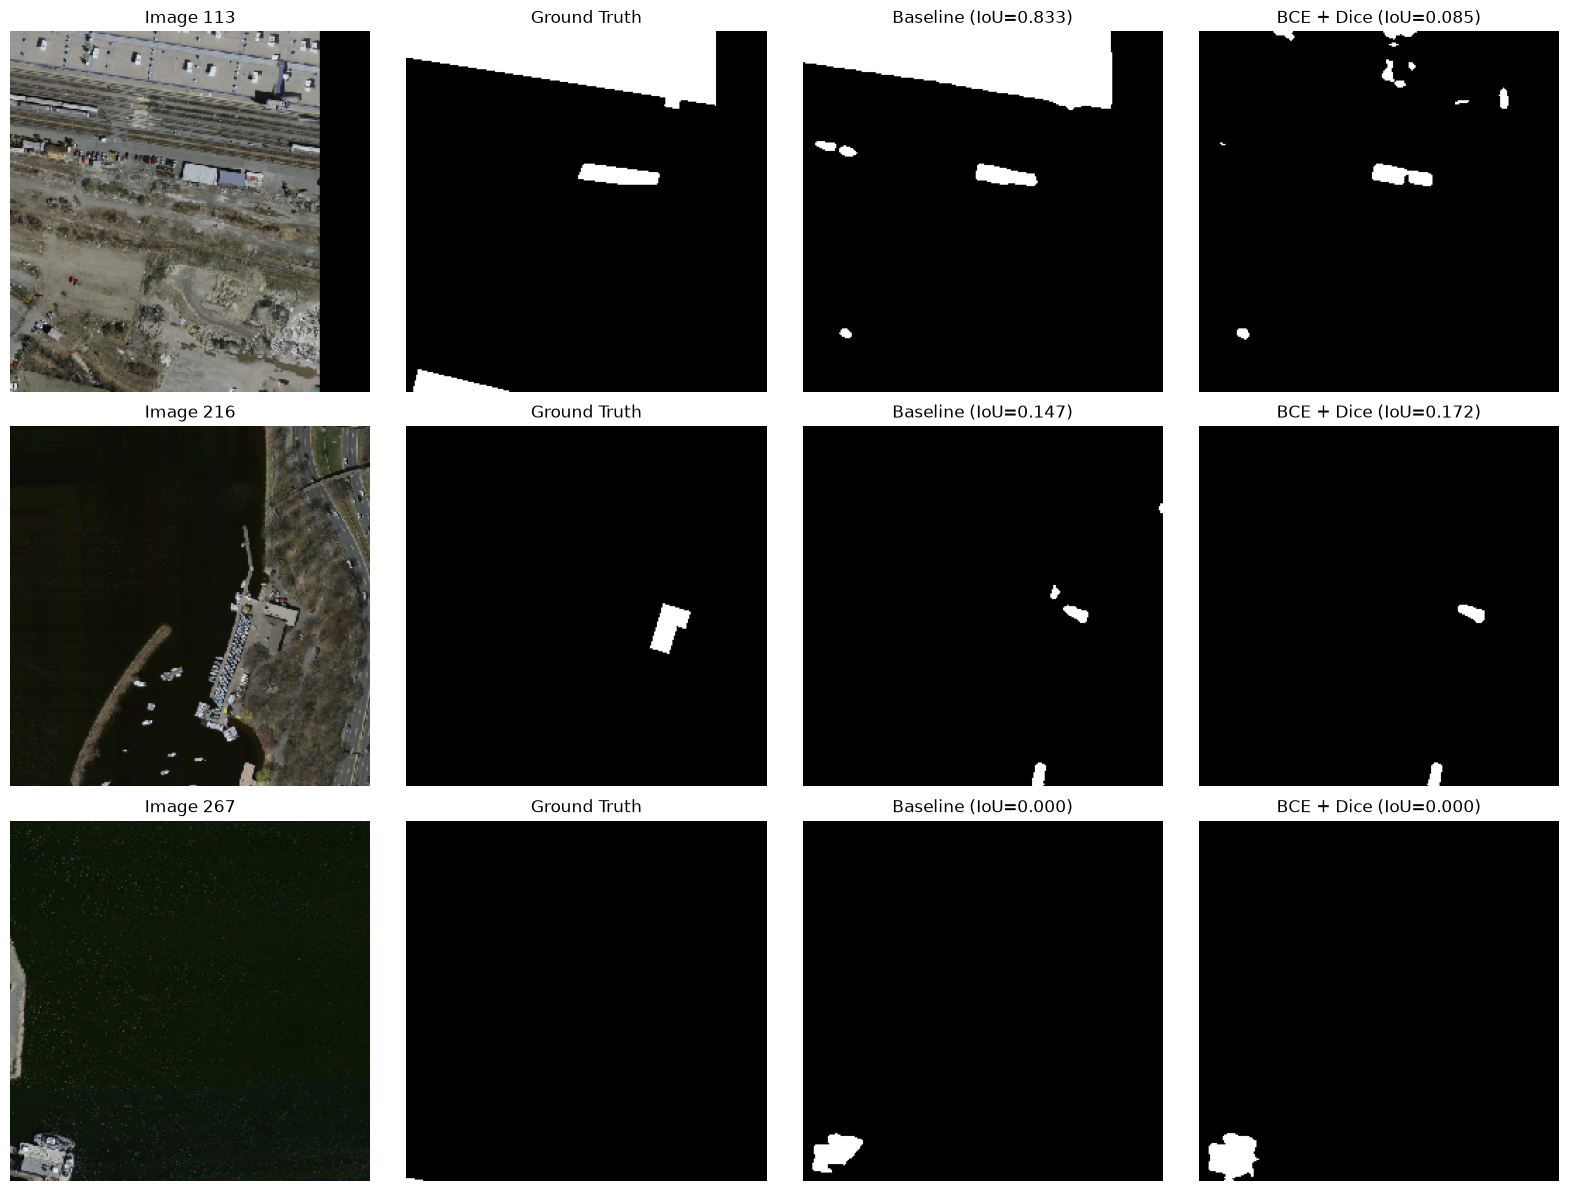

In [21]:
# Compare baseline and BCE + Dice predictions on the same test images

baseline_data = np.load(
    PROJECT_ROOT / "results/baseline_probabilities/test.npz"
)

comparison_data = np.load(
    PROJECT_ROOT / "results/comparison_probabilities/test.npz"
)

# Ensure that predictions refer to the same images in the same order
assert np.array_equal(
    baseline_data["image_paths"],
    comparison_data["image_paths"]
), "Image order does not match!"

assert np.array_equal(
    baseline_data["mask_paths"],
    comparison_data["mask_paths"]
), "Mask order does not match!"

failure_indices = [113, 216, 267]

fig, axes = plt.subplots(3, 4, figsize=(16, 12))

for row, idx in enumerate(failure_indices):

    image_path = PROJECT_ROOT / str(
        baseline_data["image_paths"][idx]
    )

    mask_path = PROJECT_ROOT / str(
        baseline_data["mask_paths"][idx]
    )

    image = np.asarray(
        Image.open(image_path).convert("RGB")
    )

    ground_truth = np.asarray(
        Image.open(mask_path).convert("L")
    ) > 0

    baseline_prediction = (
        baseline_data["probabilities"][idx, 0] >= 0.5
    )

    comparison_prediction = (
        comparison_data["probabilities"][idx, 0] >= 0.5
    )

    baseline_iou, _ = calculate_metrics(
        baseline_prediction, ground_truth
    )

    comparison_iou, _ = calculate_metrics(
        comparison_prediction, ground_truth
    )

    images = [
        image,
        ground_truth,
        baseline_prediction,
        comparison_prediction,
    ]

    titles = [
        f"Image {idx}",
        "Ground Truth",
        f"Baseline (IoU={baseline_iou:.3f})",
        f"BCE + Dice (IoU={comparison_iou:.3f})",
    ]

    for col in range(4):
        axes[row, col].imshow(
            images[col],
            cmap="gray" if col > 0 else None
        )
        axes[row, col].set_title(titles[col])
        axes[row, col].axis("off")

plt.tight_layout()

FIGURES_DIR = PROJECT_ROOT / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

plt.savefig(
    FIGURES_DIR / "failure_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()